# **Online Retail: know your metrics**

## **Know Your Metrics**

## **Monthly Revenue**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'FreeSerif', 'DejaVu Serif']

In [2]:
data = pd.read_csv('OnlineRetail.csv', encoding='latin1')
data.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [3]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

data['InvoiceYearMonth'] = data['InvoiceDate'].map(
    lambda date: 100*date.year + date.month)

data['Revenue'] = data['UnitPrice'] * data['Quantity']
data_revenue = data.groupby(['InvoiceYearMonth'])['Revenue'].sum().reset_index()
data_revenue

,InvoiceYearMonth,Revenue
0,201012,748957.020
1,201101,560000.260
2,201102,498062.650
3,201103,683267.080
4,201104,493207.121
5,201105,723333.510
6,201106,691123.120
7,201107,681300.111
8,201108,682680.510
9,201109,1019687.622


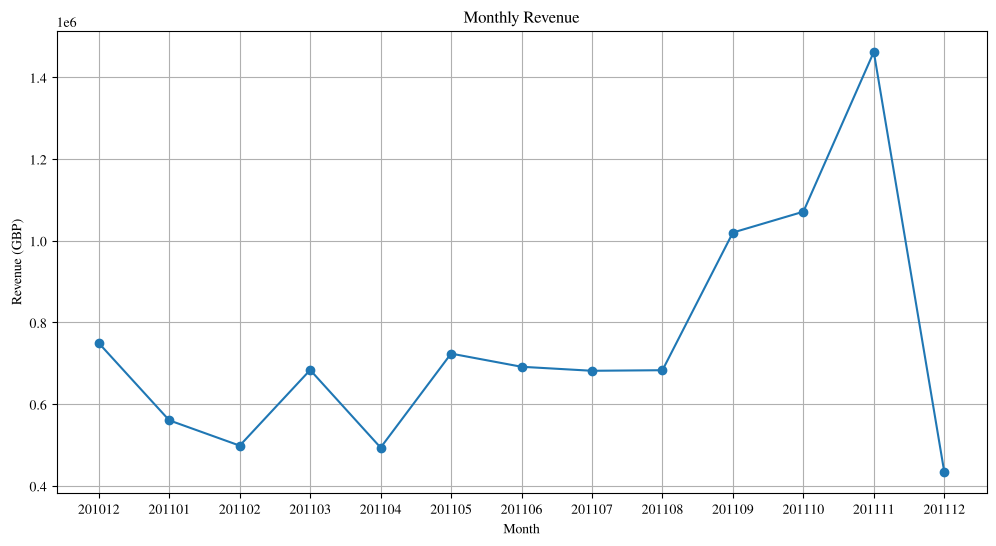

In [4]:
plt.figure(figsize=(12, 6))
plt.title('Monthly Revenue')
plt.plot(data_revenue['InvoiceYearMonth'].astype(str), data_revenue['Revenue'], marker='o')
plt.xlabel('Month')
plt.ylabel('Revenue (GBP)')
plt.grid()
plt.show()

In [5]:
data_revenue['MonthlyGrowth'] = data_revenue['Revenue'].pct_change()
data_revenue

,InvoiceYearMonth,Revenue,MonthlyGrowth
0,201012,748957.020,NaN
1,201101,560000.260,-0.252293
2,201102,498062.650,-0.110603
3,201103,683267.080,0.371850
4,201104,493207.121,-0.278163
5,201105,723333.510,0.466592
6,201106,691123.120,-0.044530
7,201107,681300.111,-0.014213
8,201108,682680.510,0.002026
9,201109,1019687.622,0.493653


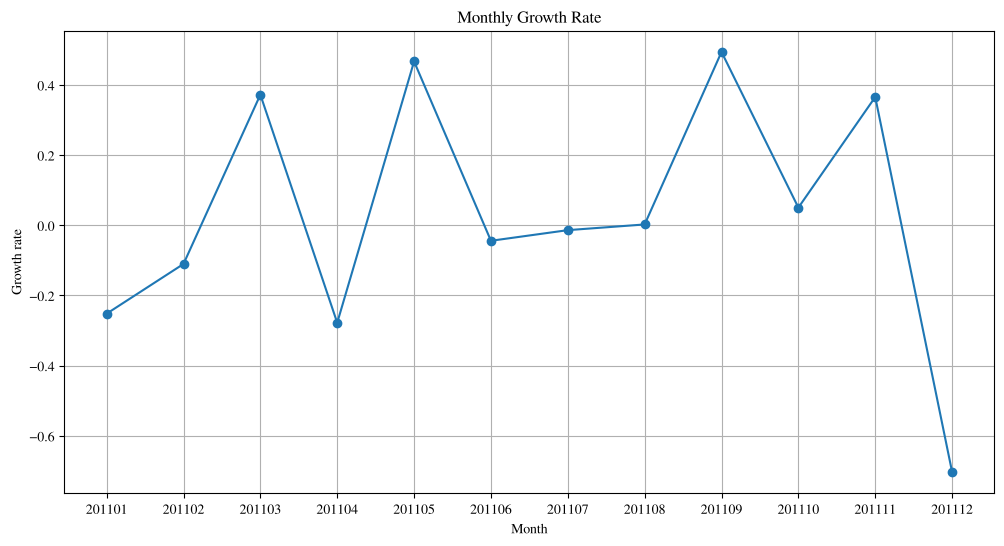

In [6]:
plt.figure(figsize=(12, 6))
plt.title('Monthly Growth Rate')
plt.plot(data_revenue['InvoiceYearMonth'].astype(
    str), data_revenue['MonthlyGrowth'], marker='o')
plt.xlabel('Month')
plt.ylabel('Growth rate')
plt.grid()
plt.show()

## **Monthly Active Customers**

In [7]:
data_uk = data.query("Country=='United Kingdom'").reset_index(drop=True)

data_monthly_active = data_uk.groupby('InvoiceYearMonth')['CustomerID'].nunique().reset_index()

data_monthly_active

,InvoiceYearMonth,CustomerID
0,201012,871
1,201101,684
2,201102,714
3,201103,923
4,201104,817
5,201105,985
6,201106,943
7,201107,899
8,201108,867
9,201109,1177


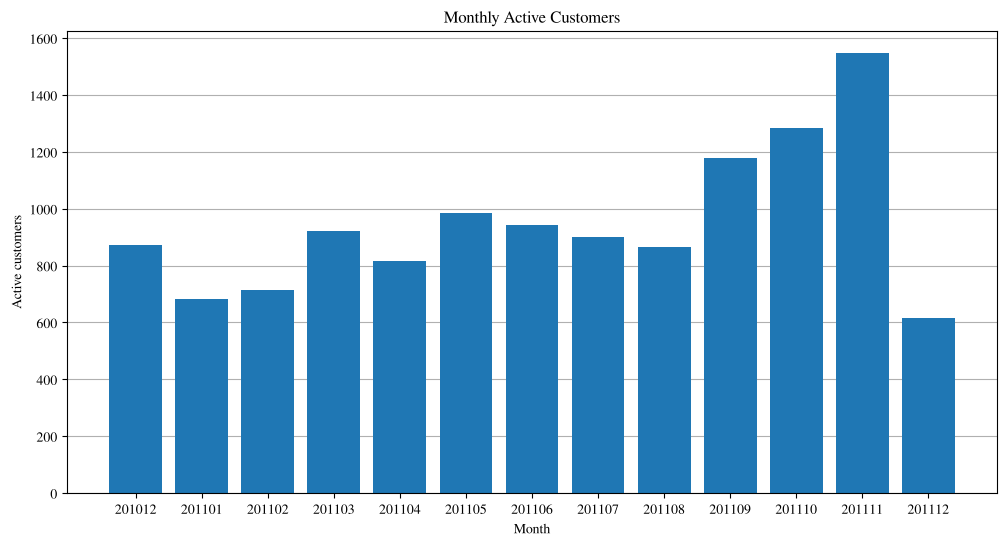

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Monthly Active Customers')
ax.bar(data_monthly_active['InvoiceYearMonth'].astype(str), data_monthly_active['CustomerID'])
ax.set_xlabel('Month')
ax.set_ylabel('Active customers')
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

### **Monthly Order Count**

In [9]:
data_monthly_sales = data_uk.groupby('InvoiceYearMonth')['Quantity'].sum().reset_index()

data_monthly_sales

,InvoiceYearMonth,Quantity
0,201012,298101
1,201101,237381
2,201102,225641
3,201103,279843
4,201104,257666
5,201105,306452
6,201106,258522
7,201107,324129
8,201108,319804
9,201109,458490


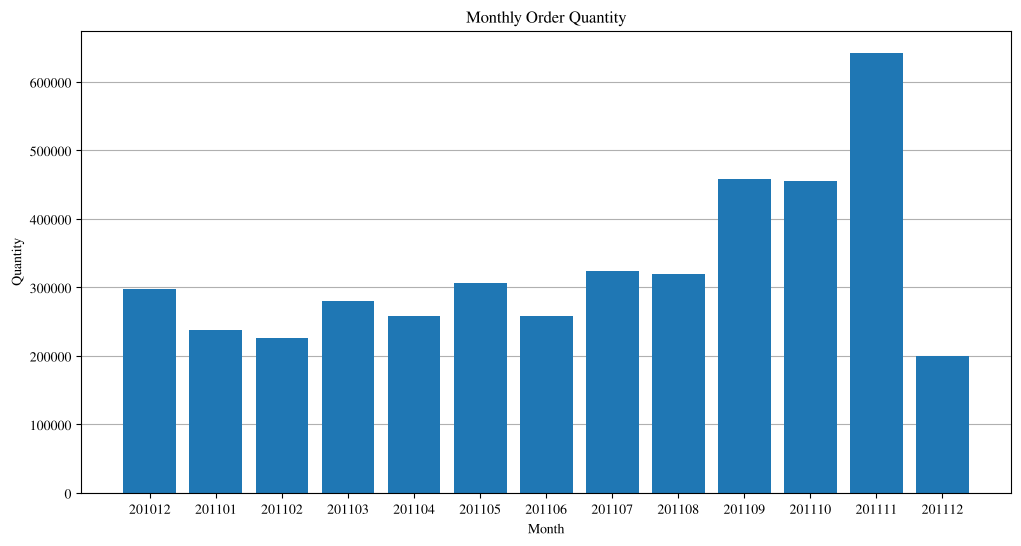

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Monthly Order Quantity')
ax.bar(data_monthly_sales['InvoiceYearMonth'].astype(str), data_monthly_sales['Quantity'])
ax.set_xlabel('Month')
ax.set_ylabel('Quantity')
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

## **Average Revenue per Order**

In [11]:
data_monthly_order_avg = data_uk.groupby('InvoiceYearMonth')[
    'Revenue'].mean().reset_index()

data_monthly_order_avg

,InvoiceYearMonth,Revenue
0,201012,16.865860
1,201101,13.614680
2,201102,16.093027
3,201103,16.716166
4,201104,15.773380
5,201105,17.713823
6,201106,16.714748
7,201107,15.723497
8,201108,17.315899
9,201109,18.931723


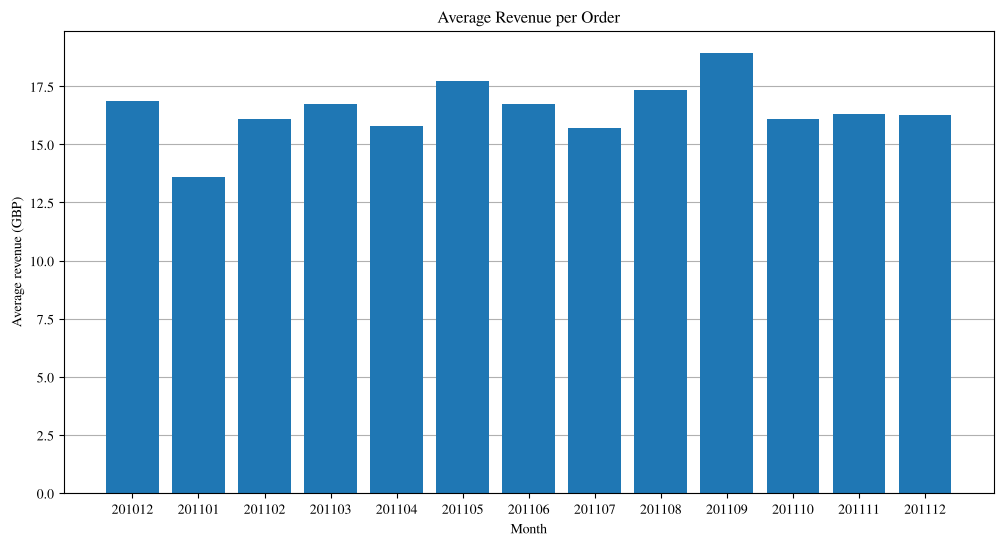

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Average Revenue per Order')
ax.bar(data_monthly_order_avg['InvoiceYearMonth'].astype(str), data_monthly_order_avg['Revenue'])
ax.set_xlabel('Month')
ax.set_ylabel('Average revenue (GBP)')
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

### **New Customer Ratio**

In [13]:
data_min_purchase = data_uk.groupby('CustomerID').InvoiceDate.min().reset_index()
data_min_purchase.columns = ['CustomerID', 'MinPurchaseDate']
data_min_purchase['MinPurchaseYearMonth'] = data_min_purchase['MinPurchaseDate'].map(
    lambda date: 100*date.year + date.month)

data_uk = pd.merge(data_uk, data_min_purchase, on='CustomerID')

data_uk.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceYearMonth,Revenue,MinPurchaseDate,MinPurchaseYearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,201012,15.30,2010-12-01 08:26:00,201012
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012,20.34,2010-12-01 08:26:00,201012
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,201012,22.00,2010-12-01 08:26:00,201012
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012,20.34,2010-12-01 08:26:00,201012
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012,20.34,2010-12-01 08:26:00,201012


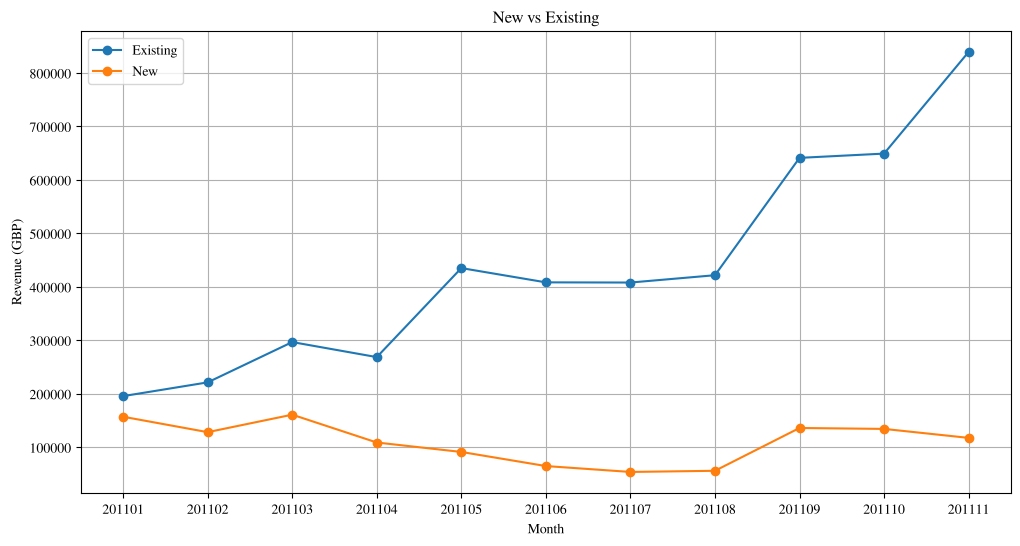

In [14]:
data_uk['UserType'] = 'New'
data_uk.loc[data_uk['InvoiceYearMonth'] > data_uk['MinPurchaseYearMonth'], 'UserType'] = 'Existing'

data_user_type_revenue = data_uk.groupby(['InvoiceYearMonth', 'UserType'])['Revenue'].sum().reset_index()

data_user_type_revenue = data_user_type_revenue.query("InvoiceYearMonth != 201012 and InvoiceYearMonth != 201112")

plt.figure(figsize=(12, 6))
plt.plot(data_user_type_revenue.query("UserType == 'Existing'")['InvoiceYearMonth'].to_numpy(dtype=str),
         data_user_type_revenue.query("UserType == 'Existing'")['Revenue'].to_numpy(), marker='o')

plt.plot(data_user_type_revenue.query("UserType == 'New'")['InvoiceYearMonth'].to_numpy(dtype=str),
         data_user_type_revenue.query("UserType == 'New'")['Revenue'].to_numpy(), marker='o')

plt.xlabel('Month')
plt.ylabel('Revenue (GBP)')
plt.title('New vs Existing')
plt.legend(['Existing', 'New'])
plt.grid()
plt.show()

In [15]:
data_new_customers = data_uk.query("UserType == 'New'").groupby(['InvoiceYearMonth'])['CustomerID'].nunique()
data_existing_customers = data_uk.query("UserType == 'Existing'").groupby(['InvoiceYearMonth'])['CustomerID'].nunique()
data_user_ratio = data_new_customers / data_existing_customers
data_user_ratio = data_user_ratio.reset_index()
data_user_ratio = data_user_ratio.dropna()

data_user_ratio

,InvoiceYearMonth,CustomerID
1,201101,1.124224
2,201102,0.904000
3,201103,0.792233
4,201104,0.510166
5,201105,0.343793
6,201106,0.281250
7,201107,0.236589
8,201108,0.192572
9,201109,0.304878
10,201110,0.328852


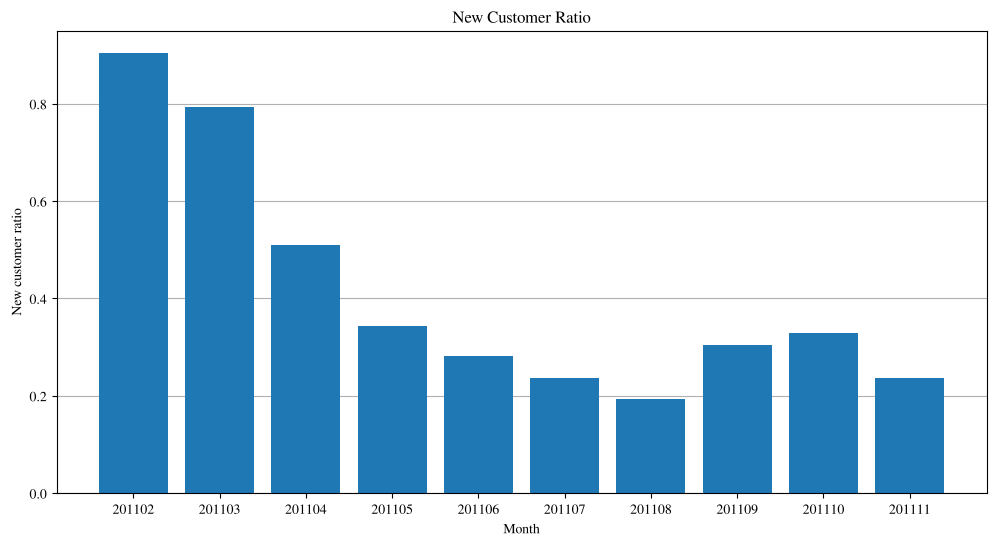

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('New Customer Ratio')
ax.bar(data_user_ratio.query("InvoiceYearMonth>201101 and InvoiceYearMonth<201112")['InvoiceYearMonth'].astype(str),
       data_user_ratio.query("InvoiceYearMonth>201101 and InvoiceYearMonth<201112")['CustomerID'])
ax.set_xlabel('Month')
ax.set_ylabel('New customer ratio')
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

### **Monthly Retention Rate**

### **Q3 (a) · Inspect the UK customer data**

In [17]:
print('UK rows:', len(data_uk))
data_uk[['InvoiceNo', 'InvoiceDate', 'InvoiceYearMonth', 'CustomerID', 'Quantity', 'UnitPrice', 'Revenue']].info()

UK rows: 361878
<class 'pandas.DataFrame'>
RangeIndex: 361878 entries, 0 to 361877
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   InvoiceNo         361878 non-null  str           
 1   InvoiceDate       361878 non-null  datetime64[us]
 2   InvoiceYearMonth  361878 non-null  int64         
 3   CustomerID        361878 non-null  float64       
 4   Quantity          361878 non-null  int64         
 5   UnitPrice         361878 non-null  float64       
 6   Revenue           361878 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(1)
memory usage: 19.3 MB


In [18]:
unusual = pd.Series({
    'UK rows without CustomerID in raw data': data[data['Country'] == 'United Kingdom']['CustomerID'].isna().sum(),
    'Rows without CustomerID in data_uk': data_uk['CustomerID'].isna().sum(),
    'Cancelled invoices (InvoiceNo starts with C)': data_uk['InvoiceNo'].astype(str).str.startswith('C').sum(),
    'Rows with Quantity <= 0': (data_uk['Quantity'] <= 0).sum(),
    'Rows with UnitPrice <= 0': (data_uk['UnitPrice'] <= 0).sum(),
    'Exact duplicate rows': data_uk.duplicated().sum()
})
unusual.rename('rows').to_frame()

,rows
UK rows without CustomerID in raw data,133600
Rows without CustomerID in data_uk,0
Cancelled invoices (InvoiceNo starts with C),7533
Rows with Quantity <= 0,7533
Rows with UnitPrice <= 0,24
Exact duplicate rows,5150


The 133,600 UK rows without `CustomerID` were removed earlier by the merge, so `data_uk` has none. Cancellations are kept, and Q3 (g) tests their effect.

### **Q3 (b) · Customer-by-month activity table**

In [19]:
data_user_purchase = data_uk.groupby(['CustomerID', 'InvoiceYearMonth'])['Revenue'].sum().reset_index()
activity = pd.crosstab(data_user_purchase['CustomerID'], data_user_purchase['InvoiceYearMonth'])
activity

InvoiceYearMonth,201012,201101,201102,201103,201104,201105,201106,201107,201108,201109,201110,201111,201112
CustomerID,,,,,,,,,,,,,
12346.0,0,1,0,0,0,0,0,0,0,0,0,0,0
12747.0,1,1,0,1,0,1,1,0,1,0,1,1,1
12748.0,1,1,1,1,1,1,1,1,1,1,1,1,1
12749.0,0,0,0,0,0,1,0,0,1,0,0,1,1
12820.0,0,1,0,0,0,0,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18280.0,0,0,0,1,0,0,0,0,0,0,0,0,0
18281.0,0,0,0,0,0,0,1,0,0,0,0,0,0
18282.0,0,0,0,0,0,0,0,0,1,0,0,0,1


### **Q3 (c) · Total active customers per month**

In [20]:
total_active = activity.sum()
total_active.rename('TotalCustomers').to_frame()

,TotalCustomers
InvoiceYearMonth,
201012,871
201101,684
201102,714
201103,923
201104,817
201105,985
201106,943
201107,899
201108,867


### **Q3 (d) · Customers active in both the current and previous month**

In [21]:
is_active = activity > 0
retained = (is_active & is_active.shift(1, axis=1, fill_value=False)).sum()
retained.rename('RetainedCustomers').to_frame()

,RetainedCustomers
InvoiceYearMonth,
201012,0
201101,322
201102,263
201103,305
201104,310
201105,369
201106,417
201107,379
201108,391


### **Q3 (e) · Retention table**

In [22]:
retention = pd.DataFrame({
    'Month': pd.to_datetime(activity.columns.astype(str), format='%Y%m').to_period('M'),
    'TotalCustomers': total_active.values,
    'RetainedCustomers': retained.values
}).iloc[1:].reset_index(drop=True)
retention['RetentionRate'] = retention['RetainedCustomers'] / retention['TotalCustomers']
retention.round({'RetentionRate': 4})

,Month,TotalCustomers,RetainedCustomers,RetentionRate
0,2011-01,684,322,0.4708
1,2011-02,714,263,0.3683
2,2011-03,923,305,0.3304
3,2011-04,817,310,0.3794
4,2011-05,985,369,0.3746
5,2011-06,943,417,0.4422
6,2011-07,899,379,0.4216
7,2011-08,867,391,0.4510
8,2011-09,1177,417,0.3543
9,2011-10,1285,502,0.3907


### **Q3 (f) · Line chart of the monthly retention rate**

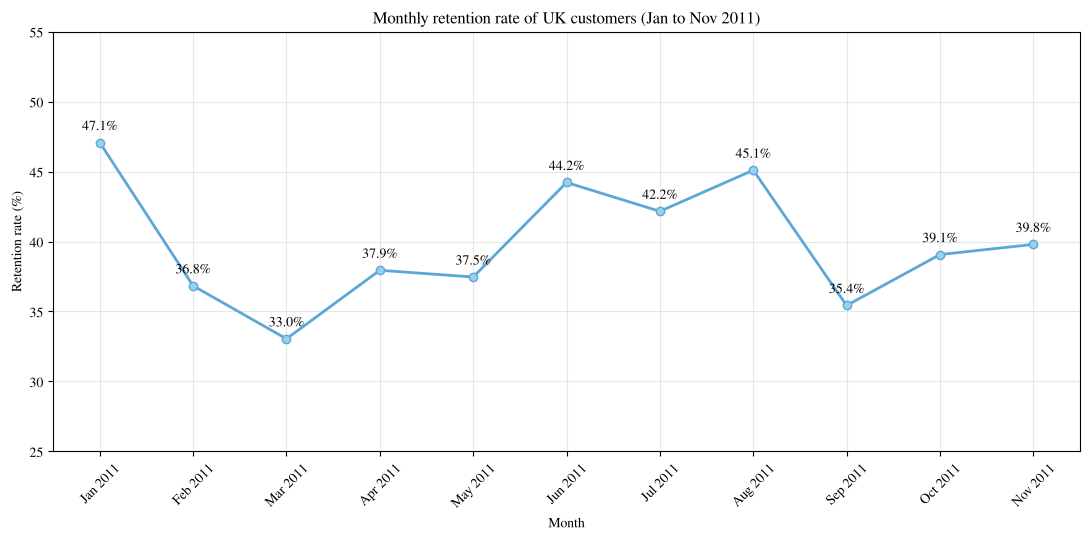

In [23]:
plot_data = retention[retention['Month'] < pd.Period('2011-12')]
rate = plot_data['RetentionRate'] * 100
months_label = plot_data['Month'].dt.strftime('%b %Y')

plt.figure(figsize=(11, 5.5))
plt.plot(months_label, rate, marker='o', color='#5BA8D6', linewidth=2, markerfacecolor='#9AD0EC', markeredgecolor='#5BA8D6')
for x, y in zip(months_label, rate):
    plt.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, 9), ha='center')
plt.title('Monthly retention rate of UK customers (Jan to Nov 2011)')
plt.xlabel('Month')
plt.ylabel('Retention rate (%)')
plt.ylim(25, 55)
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Retention starts at 47.1% in January, falls to 33.0% in March, rises to 45.1% in August, drops to 35.4% in September, and ends at 39.8% in November. About 4 in 10 active customers had also bought in the previous month.

### **Q3 (g) · Sensitivity to cancellations**

In [24]:
no_cancel = data_uk[~data_uk['InvoiceNo'].astype(str).str.startswith('C')]
pairs = no_cancel.groupby(['CustomerID', 'InvoiceYearMonth']).size().unstack(fill_value=0) > 0
rate_no_cancel = (pairs & pairs.shift(1, axis=1, fill_value=False)).sum() / pairs.sum()

comparison = retention[['Month', 'RetentionRate']].rename(columns={'RetentionRate': 'AllInvoices'})
comparison['WithoutCancellations'] = rate_no_cancel.values[1:]
comparison['Difference'] = comparison['AllInvoices'] - comparison['WithoutCancellations']
comparison[comparison['Month'] < pd.Period('2011-12')].round({'AllInvoices': 4, 'WithoutCancellations': 4, 'Difference': 4})

,Month,AllInvoices,WithoutCancellations,Difference
0,2011-01,0.4708,0.4467,0.0241
1,2011-02,0.3683,0.3432,0.0252
2,2011-03,0.3304,0.2886,0.0418
3,2011-04,0.3794,0.3495,0.0299
4,2011-05,0.3746,0.3534,0.0212
5,2011-06,0.4422,0.4139,0.0283
6,2011-07,0.4216,0.3900,0.0316
7,2011-08,0.4510,0.4245,0.0265
8,2011-09,0.3543,0.3386,0.0157
9,2011-10,0.3907,0.3618,0.0289


Cancellations raise the rate by 1.6 to 4.2 percentage points. The month-to-month pattern is the same, so the conclusions hold.

### **Cohort Based Retention Rate**

In [25]:
data_retention = pd.crosstab(data_user_purchase['CustomerID'], data_user_purchase['InvoiceYearMonth']).reset_index()
months = data_retention.columns[2:]
data_retention

InvoiceYearMonth,CustomerID,201012,201101,201102,201103,201104,201105,201106,201107,201108,201109,201110,201111,201112
0,12346.0,0,1,0,0,0,0,0,0,0,0,0,0,0
1,12747.0,1,1,0,1,0,1,1,0,1,0,1,1,1
2,12748.0,1,1,1,1,1,1,1,1,1,1,1,1,1
3,12749.0,0,0,0,0,0,1,0,0,1,0,0,1,1
4,12820.0,0,1,0,0,0,0,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3945,18280.0,0,0,0,1,0,0,0,0,0,0,0,0,0
3946,18281.0,0,0,0,0,0,0,1,0,0,0,0,0,0
3947,18282.0,0,0,0,0,0,0,0,0,1,0,0,0,1
3948,18283.0,0,1,1,0,1,1,1,1,0,1,1,1,1


In [26]:
data_retention = pd.merge(data_retention, data_min_purchase[['CustomerID', 'MinPurchaseYearMonth']], on='CustomerID')
data_retention

,CustomerID,201012,201101,201102,201103,201104,201105,201106,201107,201108,201109,201110,201111,201112,MinPurchaseYearMonth
0,12346.0,0,1,0,0,0,0,0,0,0,0,0,0,0,201101
1,12747.0,1,1,0,1,0,1,1,0,1,0,1,1,1,201012
2,12748.0,1,1,1,1,1,1,1,1,1,1,1,1,1,201012
3,12749.0,0,0,0,0,0,1,0,0,1,0,0,1,1,201105
4,12820.0,0,1,0,0,0,0,0,0,0,1,1,0,1,201101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3945,18280.0,0,0,0,1,0,0,0,0,0,0,0,0,0,201103
3946,18281.0,0,0,0,0,0,0,1,0,0,0,0,0,0,201106
3947,18282.0,0,0,0,0,0,0,0,0,1,0,0,0,1,201108
3948,18283.0,0,1,1,0,1,1,1,1,0,1,1,1,1,201101


In [27]:
new_column_names = ['m_' + str(column) for column in data_retention.columns[:-1]]
new_column_names.append('MinPurchaseYearMonth')
data_retention.columns = new_column_names
data_retention

,m_CustomerID,m_201012,m_201101,m_201102,m_201103,m_201104,m_201105,m_201106,m_201107,m_201108,m_201109,m_201110,m_201111,m_201112,MinPurchaseYearMonth
0,12346.0,0,1,0,0,0,0,0,0,0,0,0,0,0,201101
1,12747.0,1,1,0,1,0,1,1,0,1,0,1,1,1,201012
2,12748.0,1,1,1,1,1,1,1,1,1,1,1,1,1,201012
3,12749.0,0,0,0,0,0,1,0,0,1,0,0,1,1,201105
4,12820.0,0,1,0,0,0,0,0,0,0,1,1,0,1,201101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3945,18280.0,0,0,0,1,0,0,0,0,0,0,0,0,0,201103
3946,18281.0,0,0,0,0,0,0,1,0,0,0,0,0,0,201106
3947,18282.0,0,0,0,0,0,0,0,0,1,0,0,0,1,201108
3948,18283.0,0,1,1,0,1,1,1,1,0,1,1,1,1,201101


In [28]:
retention_array = []
for i in range(len(months)):
    retention_data = {}
    selected_month = months[i]
    prev_months = months[:i]
    next_months = months[i+1:]
    for prev_month in prev_months:
        retention_data[prev_month] = np.nan

    total_user_count = data_retention[data_retention.MinPurchaseYearMonth == selected_month].MinPurchaseYearMonth.count()
    retention_data['TotalUserCount'] = total_user_count
    retention_data[selected_month] = 1

    query = "MinPurchaseYearMonth == {}".format(selected_month)

    for next_month in next_months:
        new_query = query + " and {} > 0".format(str('m_' + str(next_month)))
        retention_data[next_month] = np.round(data_retention.query(new_query)['m_' + str(next_month)].sum()/total_user_count, 2)
    retention_array.append(retention_data)

data_retention = pd.DataFrame(retention_array)
data_retention.index = months

data_retention

,TotalUserCount,201101,201102,201103,201104,201105,201106,201107,201108,201109,201110,201111,201112
InvoiceYearMonth,,,,,,,,,,,,,
201101,362,1.0,0.23,0.28,0.25,0.34,0.29,0.26,0.26,0.31,0.35,0.36,0.15
201102,339,NaN,1.00,0.25,0.19,0.28,0.28,0.25,0.26,0.28,0.28,0.31,0.10
201103,408,NaN,NaN,1.00,0.19,0.26,0.22,0.23,0.17,0.26,0.24,0.29,0.09
201104,276,NaN,NaN,NaN,1.00,0.22,0.22,0.22,0.21,0.23,0.23,0.26,0.08
201105,252,NaN,NaN,NaN,NaN,1.00,0.23,0.17,0.17,0.21,0.24,0.27,0.10
201106,207,NaN,NaN,NaN,NaN,NaN,1.00,0.21,0.16,0.25,0.26,0.32,0.10
201107,172,NaN,NaN,NaN,NaN,NaN,NaN,1.00,0.20,0.19,0.23,0.28,0.11
201108,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,0.26,0.23,0.26,0.14
201109,275,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,0.29,0.33,0.12
